# Example ICA

Using simulations and real data to assess ICA

By: Catelin Smith

#### import necessary things

In [1]:
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from sklearn.metrics import root_mean_squared_error
import matplotlib.patches as mpatches
import matplotlib.lines as mlines

import random
from scipy import signal
import matplotlib.gridspec as gridspec

from geopack import geopack, t96
from noise_sim import NoiseSim
from orbit import Orbit
from orbit import Constants
from ica import ICA
from TD_noise_sim import TDNoiseSim

Load IGRF coefficients ...


### 0) Create Random Orbit

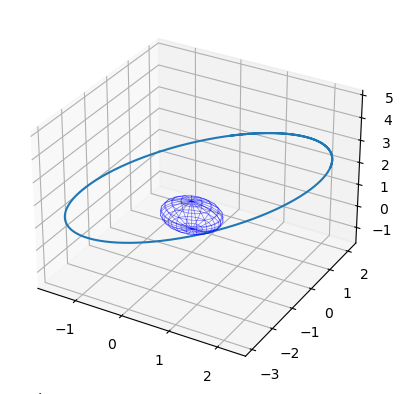

In [4]:
# create random Earth orbit

orbit_sim1 = Orbit("Earth")
r = orbit_sim1.dynamics.R
ax = plt.axes(projection='3d')

r0 = [r + random.uniform(1, 3) * r, 
      r + random.uniform(1, 3) * r, 
      r + random.uniform(1, 3) * r]
    
theta = random.uniform(0, 2 * math.pi)
phi = random.uniform(0, 2 * math.pi)
t = np.linspace(0, 85000, 5000)
    
sol = orbit_sim1.run(r0, theta, phi, t)
A = orbit_sim1.get_attitude(sol)

x = sol[:, 0] / r
y = sol[:, 1] / r
z = sol[:, 2] / r

plt.plot(sol[:, 0], sol[:, 1], sol[:, 2])
        
# Earth
u, v = np.mgrid[0:2*np.pi:20j, 0:np.pi:10j]
ax.plot_wireframe(r*np.cos(u)*np.sin(v),r*np.sin(u)*np.sin(v),
                  r*np.cos(v),color="b",alpha=0.5,lw=0.5,zorder=0)
        
plt.show()

### 1) Basic Simulation (Pure Gaussian Noise)

In [5]:
noise_sim1 = TDNoiseSim()
noise_sim2 = TDNoiseSim()
ica1 = ICA()

np.random.seed()
N  = 5000
fs = 25.0       # sample rate (Hz)
sigma = 2.0    # Gaussian noise std dev (nT)
t = np.linspace(0, 85000, 5000)

# create basic, constant magnetic field (not really accurate)

N = 5000 # num iterations

# establish scaling matrix, bias for both magnetometers
scale1 = [[0.01, -0.005, 0.008], np.deg2rad(1), np.deg2rad(0.8),
                    np.deg2rad(0.9), [np.deg2rad(0.5)]*3, np.eye(3)]
b1 = np.array([0., 0., 0.])
mtq1 = np.array([[0.5, 0.5, 0.2], [-12., 12., 10.]])

noise_sim1.set_scaling_matrix(scale1[0], scale1[1], scale1[2], scale1[3], scale1[4], scale1[5])
noise_sim1.set_bias(b1)

scale2 = [[0.02, -0.015, 0.025], np.deg2rad(1.2), np.deg2rad(0.9),
    np.deg2rad(1.1), [np.deg2rad(0.6), np.deg2rad(-0.4), np.deg2rad(0.5)],
    np.eye(3)]
b2 = np.array([0., 0., 0.])
mtq2 = np.array([[0, -0.2, 0.3], [10., -12., 13.]])

noise_sim1.set_scaling_matrix(scale2[0], scale2[1], scale2[2], scale2[3], scale2[4], scale2[5])
noise_sim2.set_bias(b2)

H_series = np.zeros((N, 3)) # measured in nT
X_obs1 = np.zeros((N, 6)) # signal / observation matrix
true_B1 = np.zeros((N, 3))

for i in range(N):
    # basic magnetic field (sinusoidal type)
    k = i / 6000 * 2 * np.pi
    H_series[i, 0] = 30.0 * np.sin(k)
    H_series[i, 1] = 25.0 * np.cos(k + 0.3)
    H_series[i, 2] = 50.0 * np.sin(k * 0.5 + 0.5)

    X_obs1[i, :3] = noise_sim1.measure_B_basic(A[:, :, i], H_series[i, :], sigma)
    true_B1[i, :] = noise_sim1.true_B
    
    X_obs1[i, 3:] = noise_sim2.measure_B_basic(A[:, :, i], H_series[i, :], sigma)

In [6]:
# compute ica
X_clean1, F1, C1, signal_idx1, noise_idx1, U1, trend1 = ica1.ica(
    X_obs1, n_sensors=2, trend_window=500, trend_passes=3
)

ica1.print_info(X_obs1, true_B1)

C coefficients:
  IC1: C=0.0188  [signal]
  IC2: C=0.6486  [NOISE]
  IC3: C=0.9592  [NOISE]
  IC4: C=0.9995  [NOISE]
  IC5: C=0.0147  [signal]
  IC6: C=0.2035  [signal]

RMSE raw:     2.2 nT
RMSE cleaned: 1.2 nT
Improvement:  47.1%


/Users/catelinsmith/Desktop/Noise Simulator/Finished : Will Upgrade Later/ica.py:419: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.02, 1, 0.97])


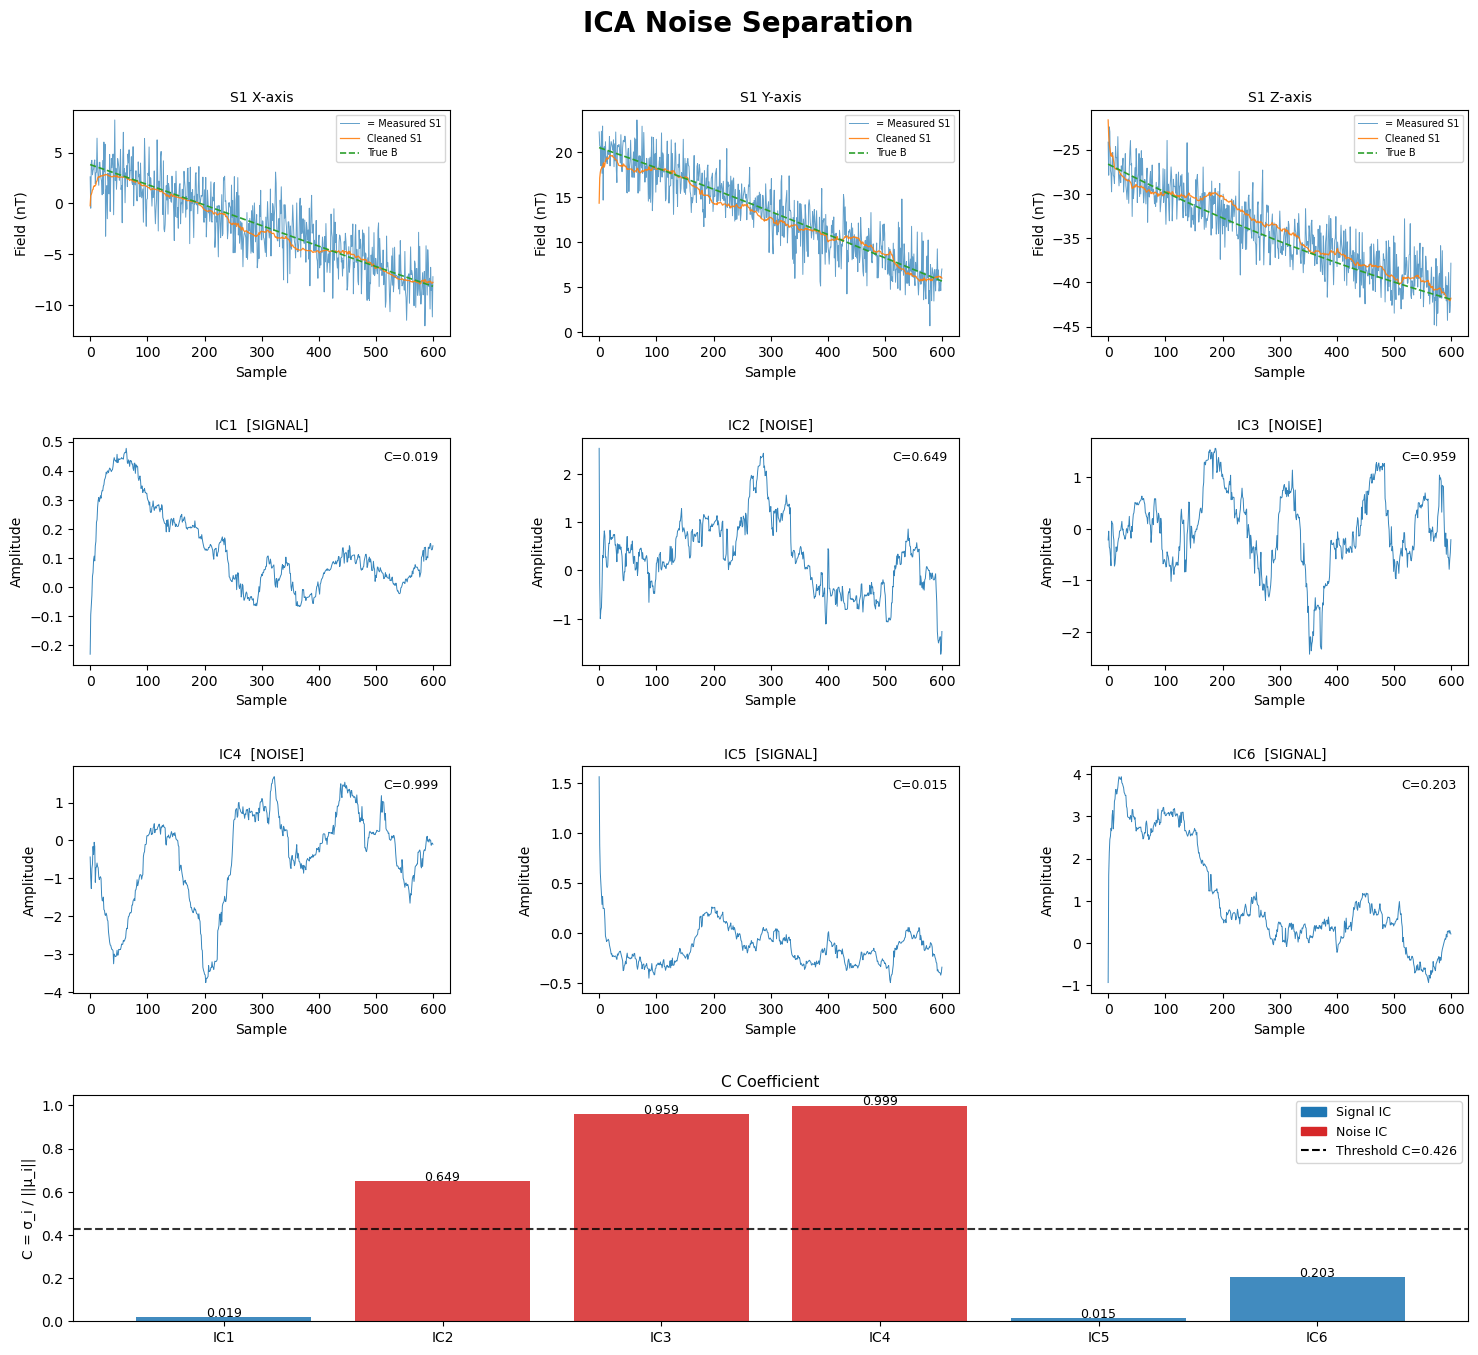

In [7]:
ica1.print_graph(X_obs1, true_B1)

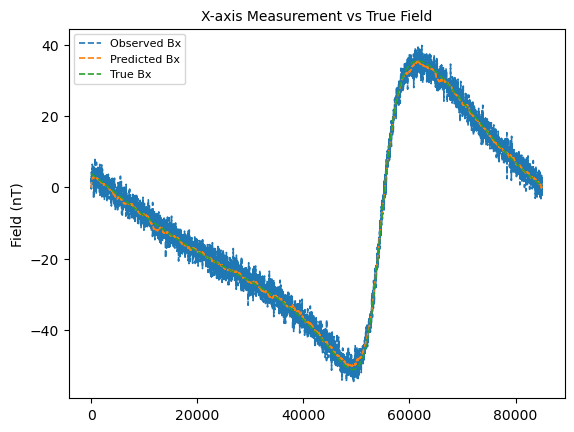

In [8]:
plt.plot(t, X_obs1[:, 0], linewidth=1.2, linestyle='--', label='Observed Bx')
plt.plot(t, X_clean1[:, 0], linewidth=1.2, linestyle='--', label='Predicted Bx')
plt.plot(t, true_B1[:, 0], linewidth=1.2, linestyle='--', label='True Bx')

plt.ylabel('Field (nT)')
plt.title('X-axis Measurement vs True Field', fontsize=10)
plt.legend(fontsize=8)

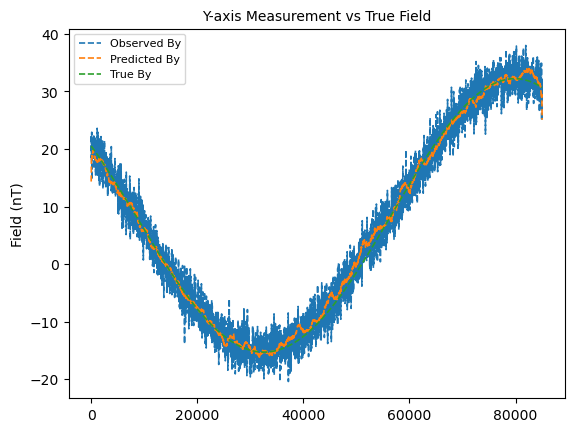

In [9]:
plt.plot(t, X_obs1[:, 1], linewidth=1.2, linestyle='--', label='Observed By')
plt.plot(t, X_clean1[:, 1], linewidth=1.2, linestyle='--', label='Predicted By')
plt.plot(t, true_B1[:, 1], linewidth=1.2, linestyle='--', label='True By')

plt.ylabel('Field (nT)')
plt.title('Y-axis Measurement vs True Field', fontsize=10)
plt.legend(fontsize=8)

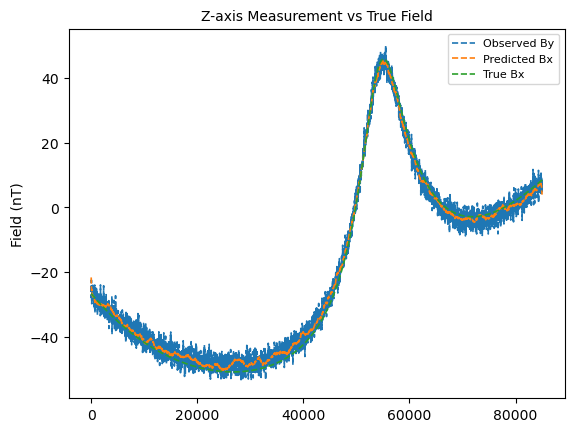

In [10]:
plt.plot(t, X_obs1[:, 2], linewidth=1.2, linestyle='--', label='Observed By')
plt.plot(t, X_clean1[:, 2], linewidth=1.2, linestyle='--', label='Predicted Bx')
plt.plot(t, true_B1[:, 2], linewidth=1.2, linestyle='--', label='True Bx')


plt.ylabel('Field (nT)')
plt.title('Z-axis Measurement vs True Field', fontsize=10)
plt.legend(fontsize=8)

In [12]:
ica1.evaluate_noise_reduction(X_obs1)

Noise-reduction evaluation (Imajo et al. 2021 style)
  sensor 1 - sensor 2 difference std per axis:
    axis 1: raw=2.88  clean=0.32  reduction=88.7%
    axis 2: raw=2.87  clean=0.72  reduction=74.8%
    axis 3: raw=3.16  clean=1.45  reduction=54.1%


{'pairwise': {(0, 1): {'raw_std': array([2.88013032, 2.86855693, 3.16373284]),
   'clean_std': array([0.32472064, 0.72323618, 1.45299529]),
   'reduction_pct': array([88.72548781, 74.78745585, 54.07338863])}},
 'events': []}

### 2) Basic Simulation (non-Gaussian Noise)

In [15]:
ica2 = ICA()

np.random.seed(42)
N  = 5000
fs = 25.0       # sample rate (Hz)
sigma = 2.0    # Gaussian noise std dev (nT)
t = np.linspace(0, 85000, 5000)

X1, true_B2 = noise_sim1.simulate_orbit_2(A, H_series, scale1, b1, mtq1, sigma, N, fs)
D1 = noise_sim1.D.copy()

scale2 = [[0.02, -0.015, 0.025], np.deg2rad(1.2), np.deg2rad(0.9),
    np.deg2rad(1.1), [np.deg2rad(0.6), np.deg2rad(-0.4), np.deg2rad(0.5)],
    np.eye(3)]
b2 = np.array([0., 0., 0.])
mtq2 = np.array([[0, -0.2, 0.3], [10., -12., 13.]])
X2, true_B2 = noise_sim2.simulate_orbit_2(A, H_series, scale2, b2, mtq2, sigma, N, fs)
D2 = noise_sim2.D.copy()

# make signal matrix
X_obs2 = np.zeros((N, 6))
X_obs2[:, :3] = X1
X_obs2[:, 3:] =  X2

In [16]:
# compute ica
X_clean2, F2, C2, signal_idx2, noise_idx2, U2, trend2 = ica2.ica(
    X_obs2, n_sensors=2, trend_window=500, trend_passes=3
)

ica2.print_info(X_obs2, true_B2)

C coefficients:
  IC1: C=0.0103  [signal]
  IC2: C=0.7965  [NOISE]
  IC3: C=0.4977  [NOISE]
  IC4: C=0.6201  [NOISE]
  IC5: C=0.0043  [signal]
  IC6: C=0.3771  [signal]

RMSE raw:     7.3 nT
RMSE cleaned: 1.1 nT
Improvement:  84.6%


/Users/catelinsmith/Desktop/Noise Simulator/Finished : Will Upgrade Later/ica.py:419: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.02, 1, 0.97])


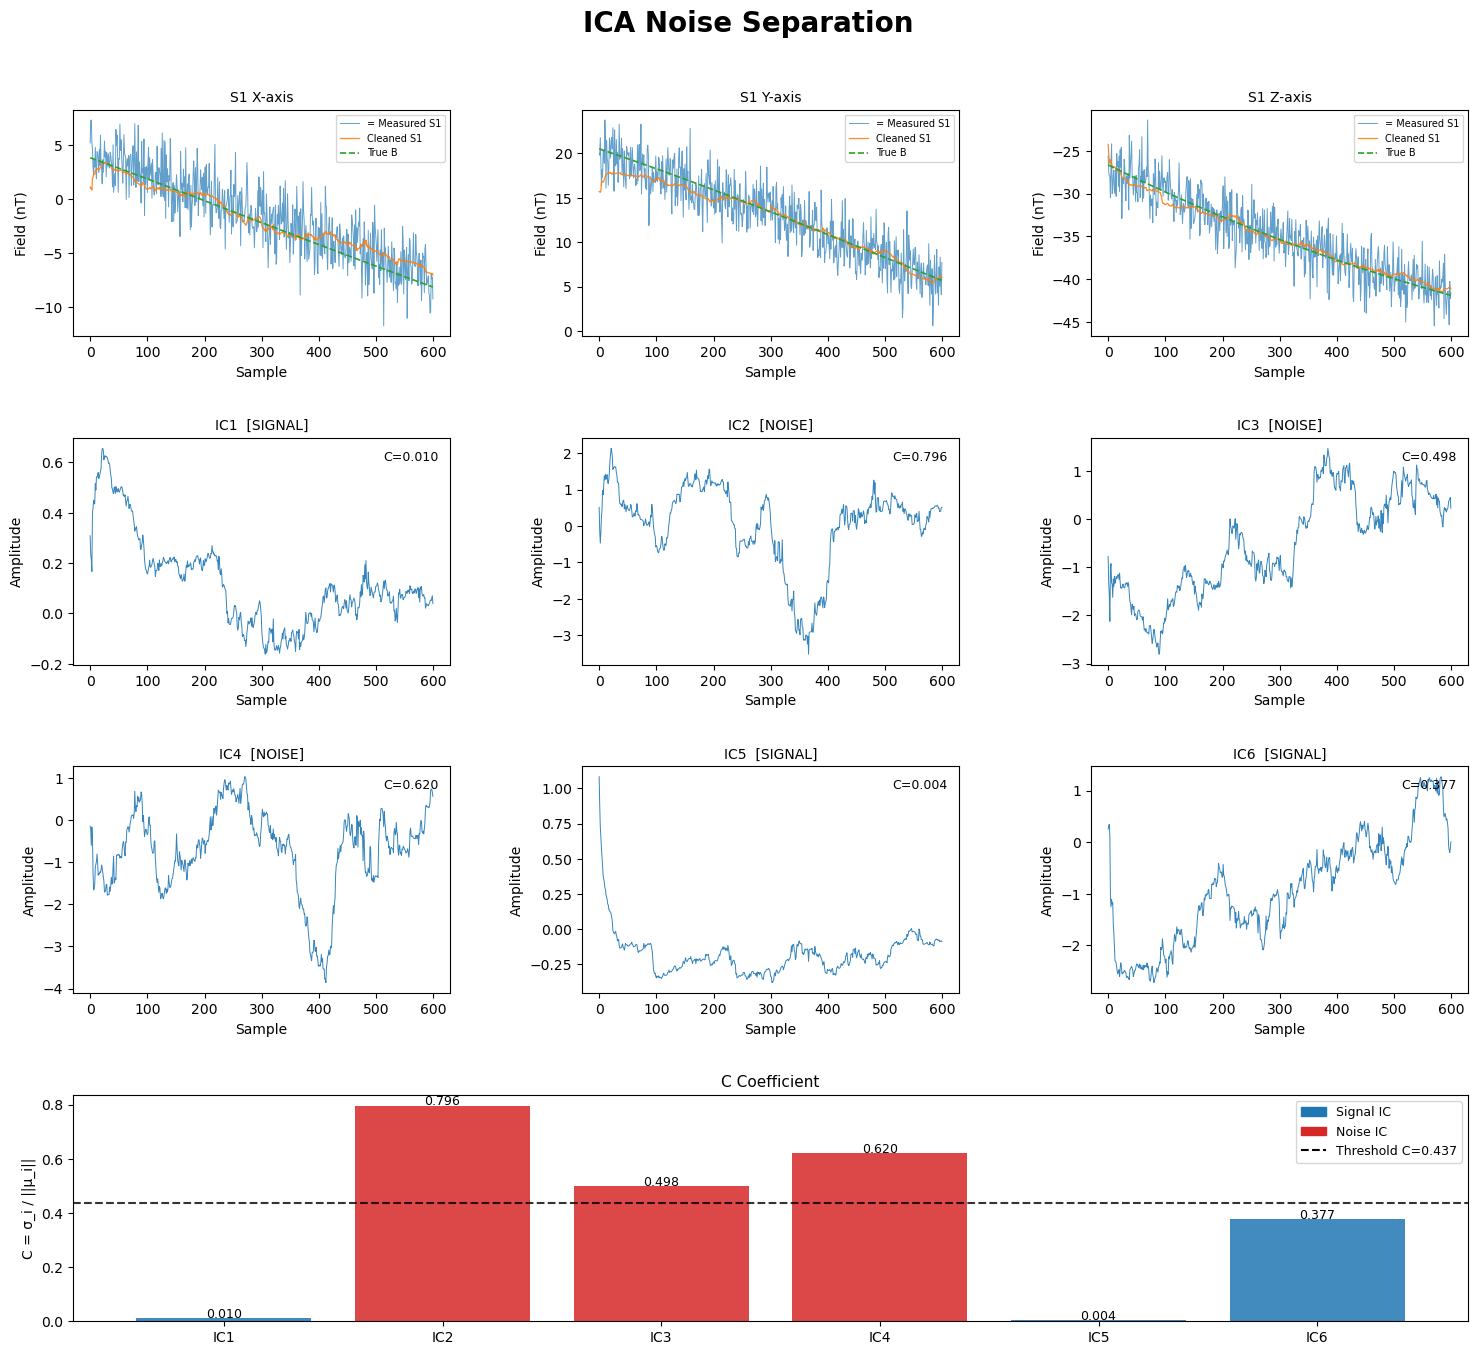

In [17]:
ica2.print_graph(X_obs2, true_B2)

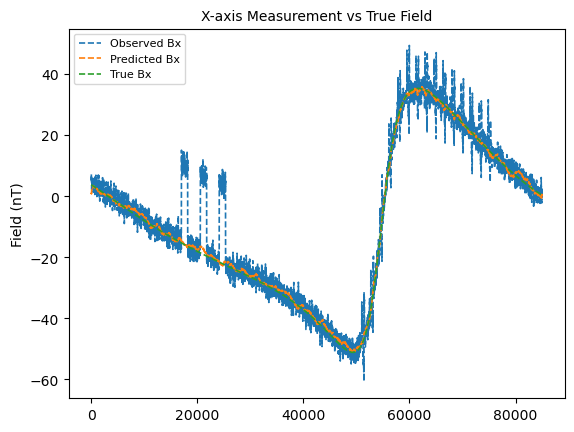

In [18]:
plt.plot(t, X_obs2[:, 0], linewidth=1.2, linestyle='--', label='Observed Bx')
plt.plot(t, X_clean2[:, 0], linewidth=1.2, linestyle='--', label='Predicted Bx')
plt.plot(t, true_B2[:, 0], linewidth=1.2, linestyle='--', label='True Bx')

plt.ylabel('Field (nT)')
plt.title('X-axis Measurement vs True Field', fontsize=10)
plt.legend(fontsize=8)

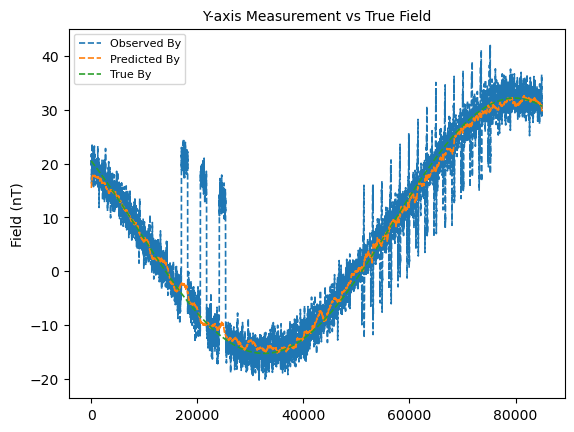

In [19]:
plt.plot(t, X_obs2[:, 1], linewidth=1.2, linestyle='--', label='Observed By')
plt.plot(t, X_clean2[:, 1], linewidth=1.2, linestyle='--', label='Predicted By')
plt.plot(t, true_B2[:, 1], linewidth=1.2, linestyle='--', label='True By')

plt.ylabel('Field (nT)')
plt.title('Y-axis Measurement vs True Field', fontsize=10)
plt.legend(fontsize=8)

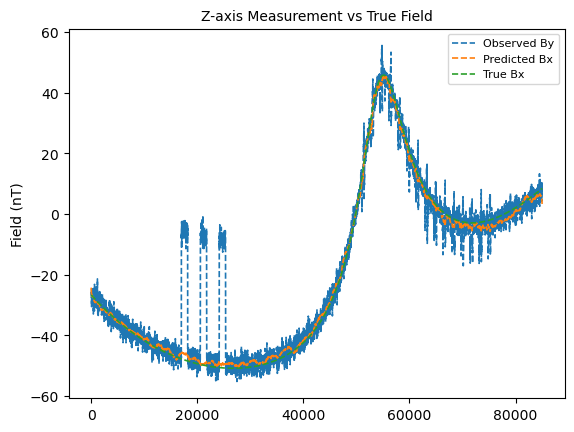

In [20]:
plt.plot(t, X_obs2[:, 2], linewidth=1.2, linestyle='--', label='Observed By')
plt.plot(t, X_clean2[:, 2], linewidth=1.2, linestyle='--', label='Predicted Bx')
plt.plot(t, true_B2[:, 2], linewidth=1.2, linestyle='--', label='True Bx')

plt.ylabel('Field (nT)')
plt.title('Z-axis Measurement vs True Field', fontsize=10)
plt.legend(fontsize=8)

### 3) Complex Simulation (Simplest Parameters)

In [22]:
noise_sim2 = TDNoiseSim()
ica3 = ICA()

np.random.seed()

ut = 100
xgsm = -5.1
ygsm = 0.3
zgsm = 2.8

ps = 10.0

#1: solar wind dynamic pressure in nPa (typically btwn 0.5 and 3 nPa)
#2: Dst index (measured space weather activity, nT)
#3-4: B component y, z direction of IMF
par = [1., -10., 2, -5., 0., 0., ps, xgsm,ygsm,zgsm]

H_series2 = np.zeros((N, 3))

for i in range(N):
    ps = geopack.recalc(ut)
    bxgsm,bygsm,bzgsm = t96.t96(par, ps, x[i], y[i], z[i])
    
    H_series2[i, 0] = bxgsm
    H_series2[i, 1] = bygsm
    H_series2[i, 2] = bzgsm
    
    ut = ut + 17
    

X1, true_B3 = noise_sim1.simulate_orbit_2(A, H_series2, scale1, b1, mtq1, sigma, N, fs)
D1 = noise_sim1.D.copy()  # ground-truth scale/misalignment matrix for sensor 1

scale2 = [[0.02, -0.015, 0.025], np.deg2rad(1.2), np.deg2rad(0.9),
    np.deg2rad(1.1), [np.deg2rad(0.6), np.deg2rad(-0.4), np.deg2rad(0.5)],
    np.eye(3)]
b2 = np.array([0., 0., 0.])
mtq2 = np.array([[0, -0.2, 0.3], [10., -12., 13.]])
X2, true_B3 = noise_sim2.simulate_orbit_2(A, H_series2, scale2, b2, mtq2, sigma, N, fs)
D2 = noise_sim2.D.copy()  # ground-truth scale/misalignment matrix for sensor 2

# make signal matrix
X_obs3 = np.zeros((N, 6))
X_obs3[:, :3] = X1
X_obs3[:, 3:] =  X2

In [23]:
# compute ica
X_clean3, F3, C3, signal_idx3, noise_idx3, U3, trend3 = ica3.ica(
    X_obs3, n_sensors=2, trend_window=500, trend_passes=3
)

ica3.print_info(X_obs3, true_B3)

C coefficients:
  IC1: C=0.4608  [NOISE]
  IC2: C=3.2816  [NOISE]
  IC3: C=0.3740  [NOISE]
  IC4: C=0.0396  [signal]
  IC5: C=0.0137  [signal]
  IC6: C=0.0142  [signal]

RMSE raw:     7.3 nT
RMSE cleaned: 1.2 nT
Improvement:  83.1%


/Users/catelinsmith/Desktop/Noise Simulator/Finished : Will Upgrade Later/ica.py:419: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.02, 1, 0.97])


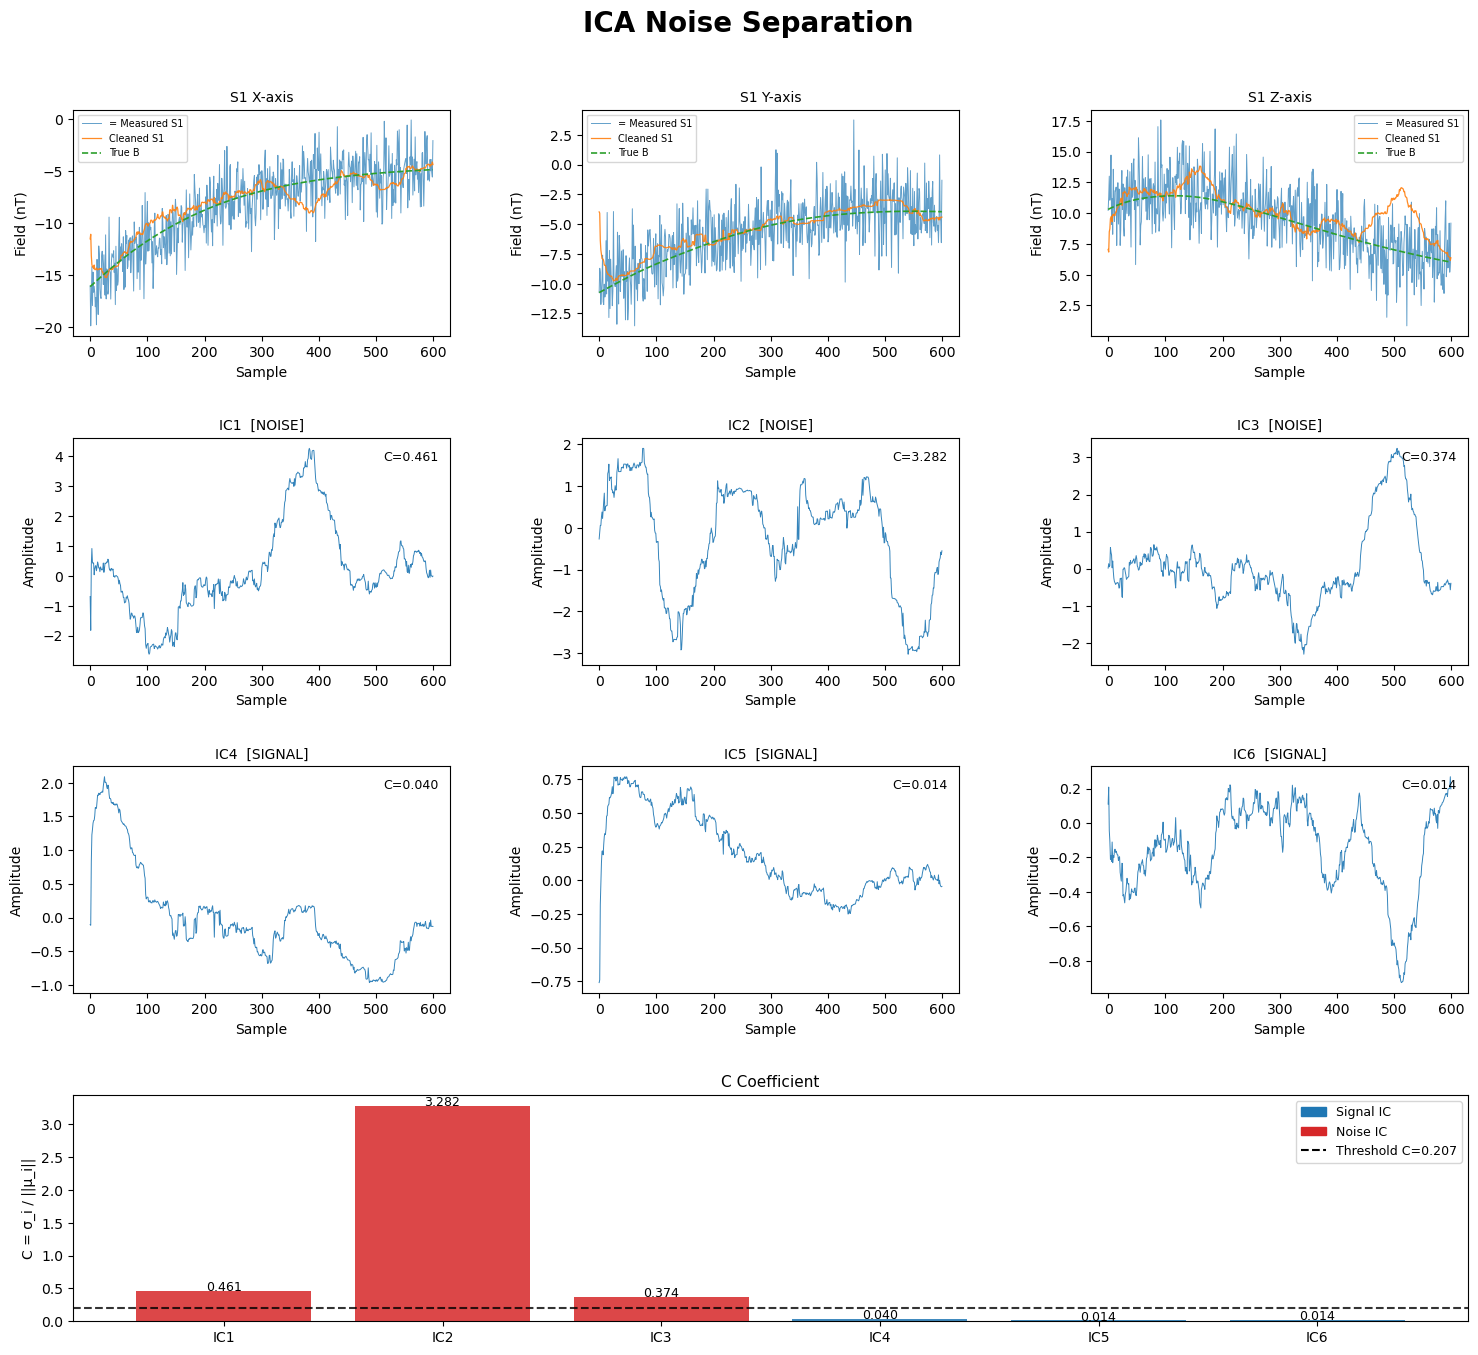

In [24]:
ica3.print_graph(X_obs3, true_B3)

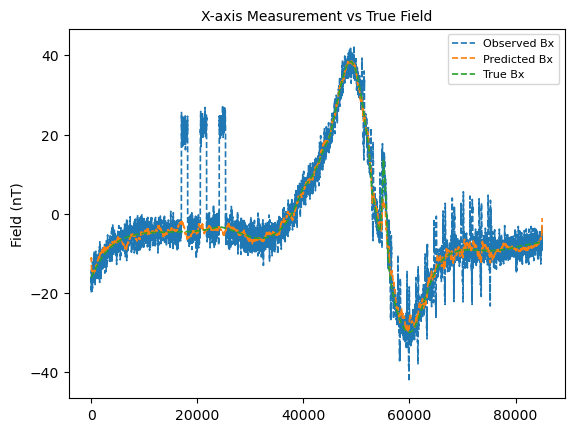

In [25]:
plt.plot(t, X_obs3[:, 0], linewidth=1.2, linestyle='--', label='Observed Bx')
plt.plot(t, X_clean3[:, 0], linewidth=1.2, linestyle='--', label='Predicted Bx')
plt.plot(t, true_B3[:, 0], linewidth=1.2, linestyle='--', label='True Bx')

plt.ylabel('Field (nT)')
plt.title('X-axis Measurement vs True Field', fontsize=10)
plt.legend(fontsize=8)

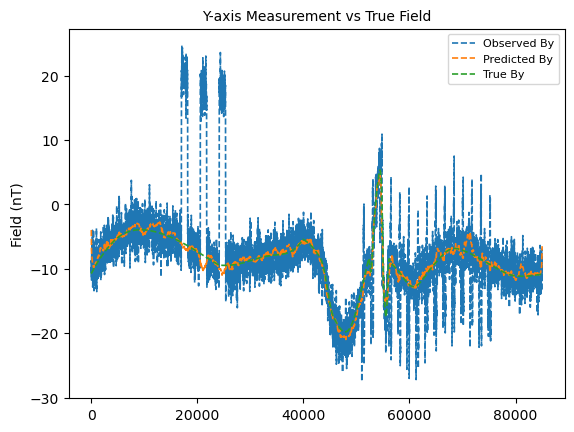

In [26]:
plt.plot(t, X_obs3[:, 1], linewidth=1.2, linestyle='--', label='Observed By')
plt.plot(t, X_clean3[:, 1], linewidth=1.2, linestyle='--', label='Predicted By')
plt.plot(t, true_B3[:, 1], linewidth=1.2, linestyle='--', label='True By')

plt.ylabel('Field (nT)')
plt.title('Y-axis Measurement vs True Field', fontsize=10)
plt.legend(fontsize=8)

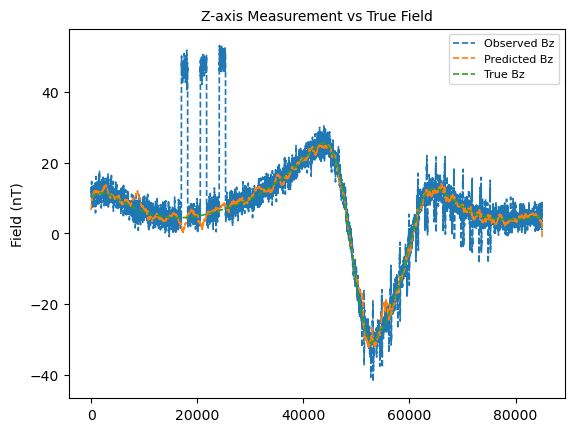

In [27]:
plt.plot(t, X_obs3[:, 2], linewidth=1.2, linestyle='--', label='Observed Bz')
plt.plot(t, X_clean3[:, 2], linewidth=1.2, linestyle='--', label='Predicted Bz')
plt.plot(t, true_B3[:, 2], linewidth=1.2, linestyle='--', label='True Bz')


plt.ylabel('Field (nT)')
plt.title('Z-axis Measurement vs True Field', fontsize=10)
plt.legend(fontsize=8)

### 4) Complex Simulation (Space Weather Event)

In [28]:
np.random.seed()

ut = 100
xgsm = -5.1
ygsm = 0.3
zgsm = 2.8

ps = 10.0

#1: solar wind dynamic pressure in nPa (typically btwn 0.5 and 3 nPa)
#2: Dst index (measured space weather activity, nT)
#3-4: B component y, z direction of IMF
par = [100., -1000., 2, -5., 0., 0., ps, xgsm,ygsm,zgsm]

H_series3 = np.zeros((N, 3))

for i in range(N):
    ps = geopack.recalc(ut)
    bxgsm,bygsm,bzgsm = t96.t96(par, ps, x[i], y[i], z[i])
    
    H_series3[i, 0] = bxgsm
    H_series3[i, 1] = bygsm
    H_series3[i, 2] = bzgsm
    
    ut = ut + 17
    

X1, true_B4 = noise_sim1.simulate_orbit_2(A, H_series3, scale1, b1, mtq1, sigma, N, fs)
D1 = noise_sim1.D.copy()

scale2 = [[0.02, -0.015, 0.025], np.deg2rad(1.2), np.deg2rad(0.9),
    np.deg2rad(1.1), [np.deg2rad(0.6), np.deg2rad(-0.4), np.deg2rad(0.5)],
    np.eye(3)]
b2 = np.array([0., 0., 0.])
mtq2 = np.array([[0, -0.2, 0.3], [10., -12., 13.]])
X2, true_B4 = noise_sim2.simulate_orbit_2(A, H_series3, scale2, b2, mtq2, sigma, N, fs)
D2 = noise_sim2.D.copy()

# make signal matrix
X_obs4 = np.zeros((N, 6))
X_obs4[:, :3] = X1
X_obs4[:, 3:] =  X2

In [29]:
# compute ica
X_clean4, F4, C4, signal_idx4, noise_idx4, U4, trend4 = ica3.ica(
    X_obs4, n_sensors=2, trend_window=500, trend_passes=3
)

ica3.print_info(X_obs4, true_B4)

C coefficients:
  IC1: C=0.0114  [signal]
  IC2: C=0.0400  [NOISE]
  IC3: C=0.2194  [NOISE]
  IC4: C=0.0125  [signal]
  IC5: C=0.0096  [signal]
  IC6: C=0.2279  [NOISE]

RMSE raw:     8.6 nT
RMSE cleaned: 15.0 nT
Improvement:  -74.7%


/Users/catelinsmith/Desktop/Noise Simulator/Finished : Will Upgrade Later/ica.py:419: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.02, 1, 0.97])


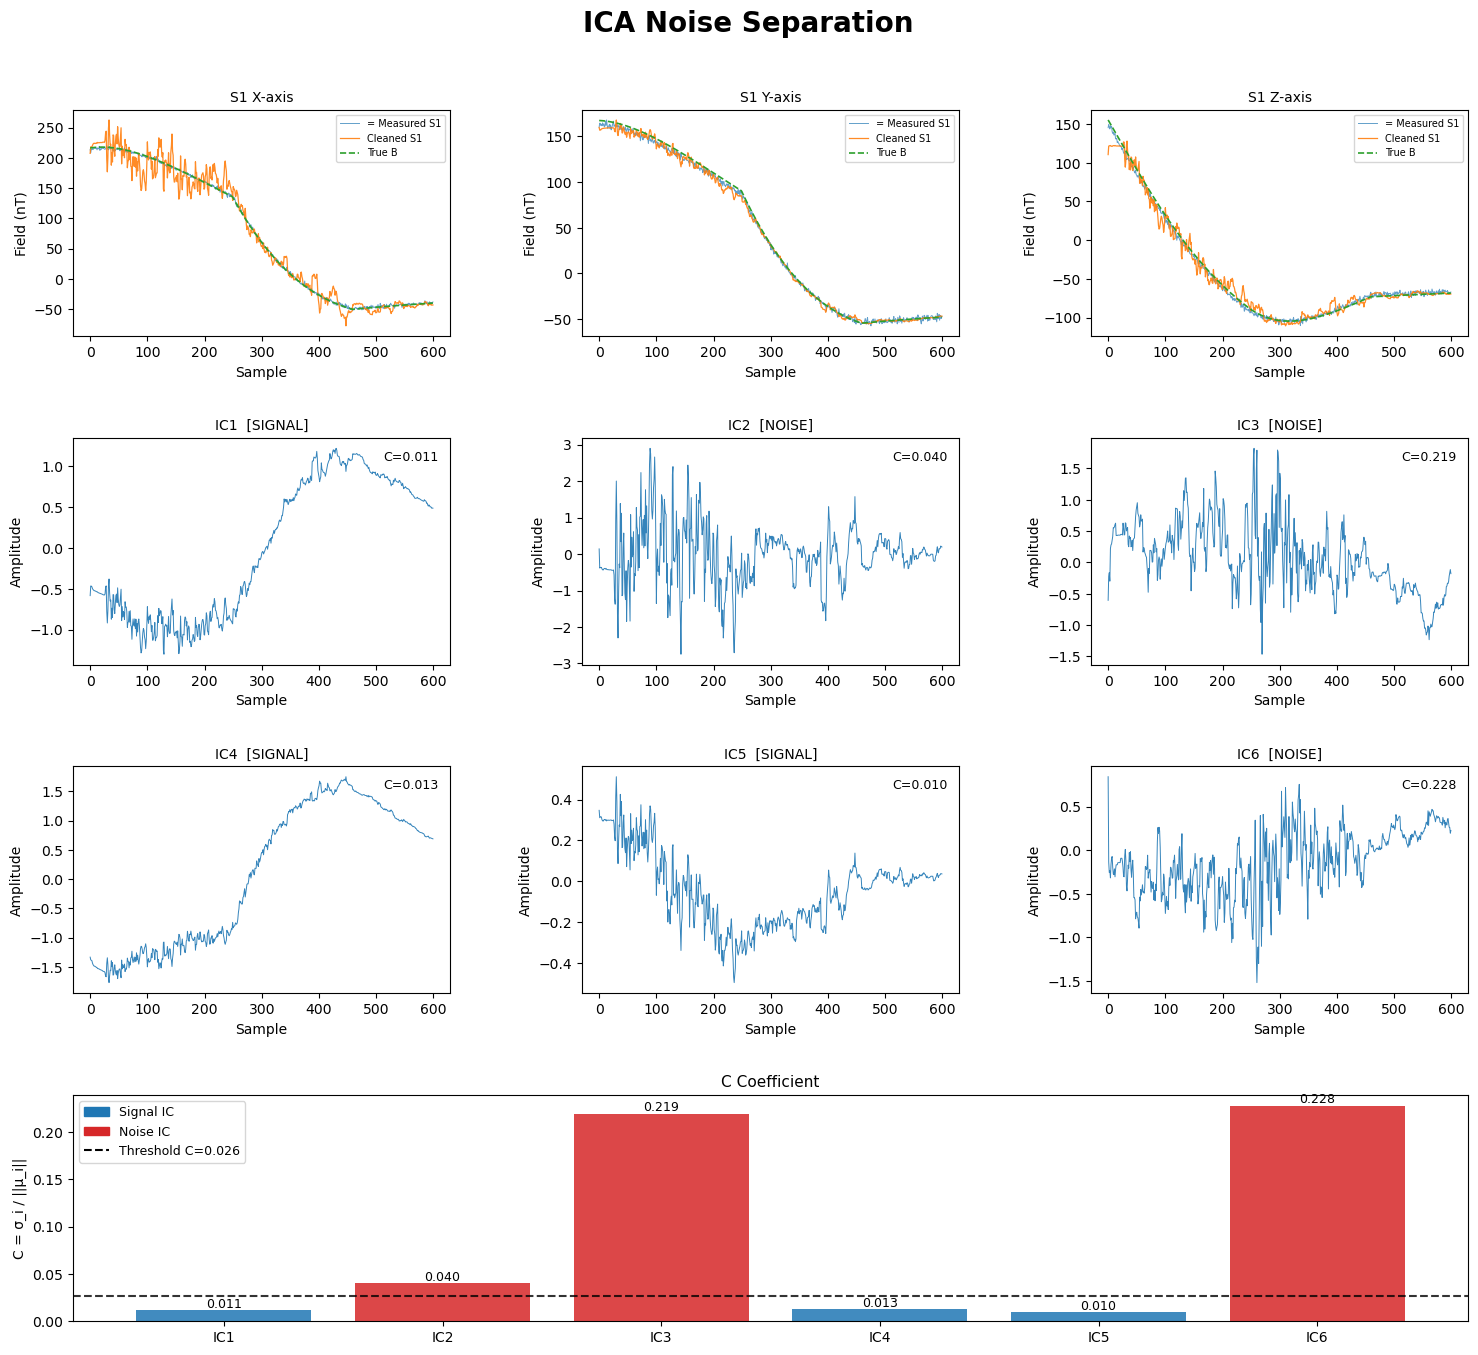

In [30]:
ica3.print_graph(X_obs4, true_B4)

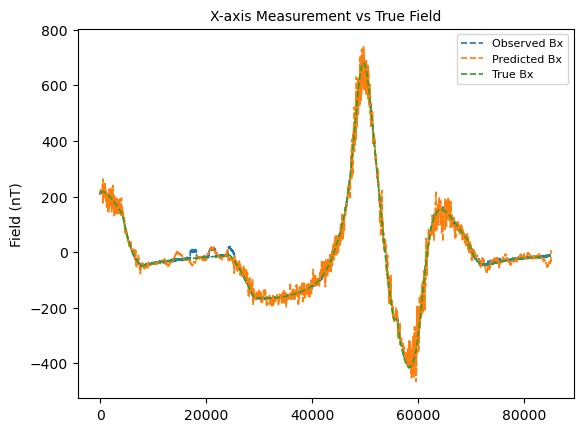

In [31]:
plt.plot(t, X_obs4[:, 0], linewidth=1.2, linestyle='--', label='Observed Bx')
plt.plot(t, X_clean4[:, 0], linewidth=1.2, linestyle='--', label='Predicted Bx')
plt.plot(t, true_B4[:, 0], linewidth=1.2, linestyle='--', label='True Bx')

plt.ylabel('Field (nT)')
plt.title('X-axis Measurement vs True Field', fontsize=10)
plt.legend(fontsize=8)

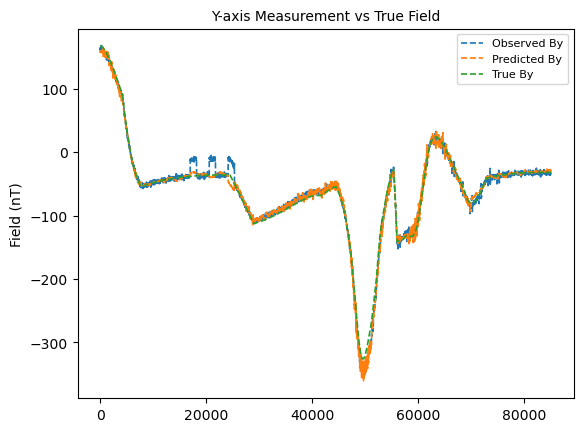

In [32]:
plt.plot(t, X_obs4[:, 1], linewidth=1.2, linestyle='--', label='Observed By')
plt.plot(t, X_clean4[:, 1], linewidth=1.2, linestyle='--', label='Predicted By')
plt.plot(t, true_B4[:, 1], linewidth=1.2, linestyle='--', label='True By')

plt.ylabel('Field (nT)')
plt.title('Y-axis Measurement vs True Field', fontsize=10)
plt.legend(fontsize=8)

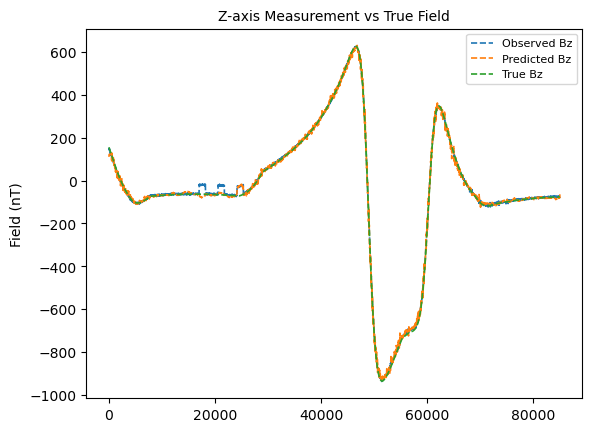

In [33]:
plt.plot(t, X_obs4[:, 2], linewidth=1.2, linestyle='--', label='Observed Bz')
plt.plot(t, X_clean4[:, 2], linewidth=1.2, linestyle='--', label='Predicted Bz')
plt.plot(t, true_B4[:, 2], linewidth=1.2, linestyle='--', label='True Bz')


plt.ylabel('Field (nT)')
plt.title('Z-axis Measurement vs True Field', fontsize=10)
plt.legend(fontsize=8)

### 5) Real Data

find out exactly what this is-- put link??

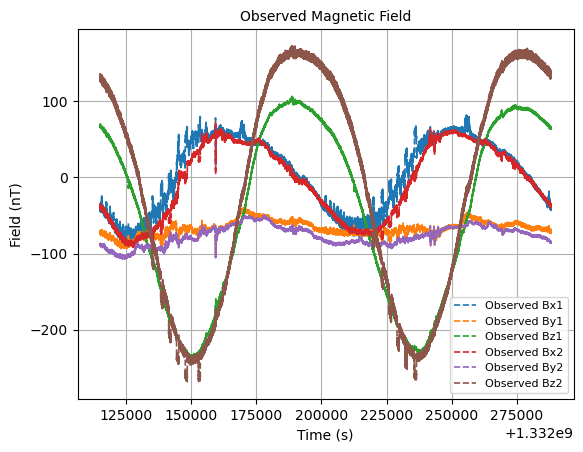

In [36]:
# read in magnetometer data
df = pd.read_csv('20120319.dat', sep=r'\s+', header=None)
df2 = pd.read_csv('20120320.dat', sep=r'\s+', header=None)

mag = df.to_numpy()
mag2 = df2.to_numpy()

mag = np.vstack((mag, mag2))

# create observation / measurement matrix
t = mag[:, 0]
X_obs5 = mag[:, 4:10]

# subtract given magnetometer biases
X_obs5 = X_obs5 - np.array([60, 410, -202, -528, -200, 474]).T

labels = ["Observed Bx1", "Observed By1", "Observed Bz1", "Observed Bx2", "Observed By2", "Observed Bz2"]

plt.plot(t, X_obs5, linewidth=1.2, linestyle='--', label=labels)

plt.ylabel('Field (nT)')
plt.xlabel('Time (s)')
plt.title('Observed Magnetic Field', fontsize=10)
plt.grid()
plt.legend(fontsize=8)

In [37]:
# implement ICA
ica5 = ICA()

X_clean5, F5, C5, signal_idx5, noise_idx5, U5, trend5 = ica5.ica(
    X_obs5, n_sensors=2, trend_window=5000, trend_passes=3
)

### update the plotting function -- make one for all these graphs

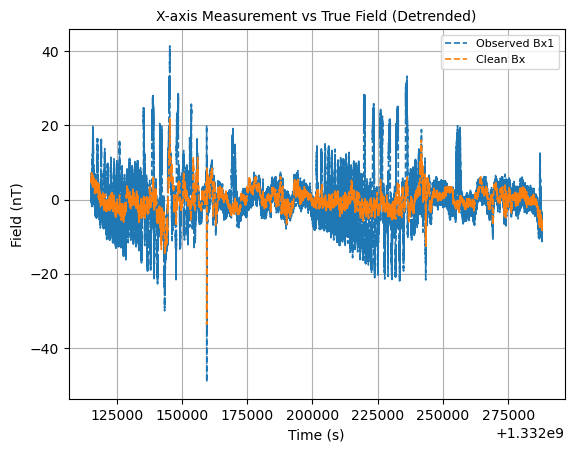

In [39]:
plt.plot(t, X_obs5[:, 0] - trend5[:, 0], linewidth=1.2, linestyle='--', label='Observed Bx1')
plt.plot(t, X_clean5[:, 0] - trend5[:, 0], linewidth=1.2, linestyle='--', label='Clean Bx')

plt.ylabel('Field (nT)')
plt.xlabel('Time (s)')
plt.grid()
plt.title('X-axis Measurement vs True Field (Detrended)', fontsize=10)
plt.legend(fontsize=8)

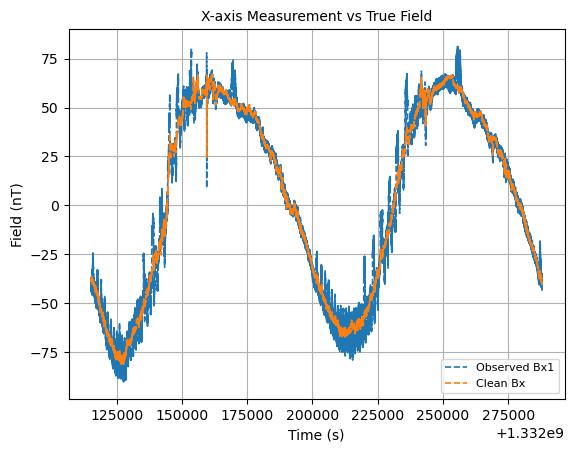

In [40]:
plt.plot(t, X_obs5[:, 0], linewidth=1.2, linestyle='--', label='Observed Bx1')
plt.plot(t, X_clean5[:, 0], linewidth=1.2, linestyle='--', label='Clean Bx')

plt.ylabel('Field (nT)')
plt.xlabel('Time (s)')
plt.grid()
plt.title('X-axis Measurement vs True Field', fontsize=10)
plt.legend(fontsize=8)

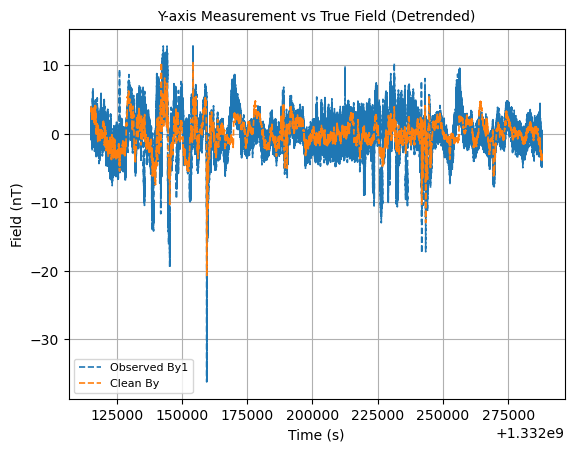

In [41]:
plt.plot(t, X_obs5[:, 1] - trend5[:, 1], linewidth=1.2, linestyle='--', label='Observed By1')
plt.plot(t, X_clean5[:, 4] - trend5[:, 4], linewidth=1.2, linestyle='--', label='Clean By')

plt.ylabel('Field (nT)')
plt.xlabel('Time (s)')
plt.grid()
plt.title('Y-axis Measurement vs True Field (Detrended)', fontsize=10)
plt.legend(fontsize=8)

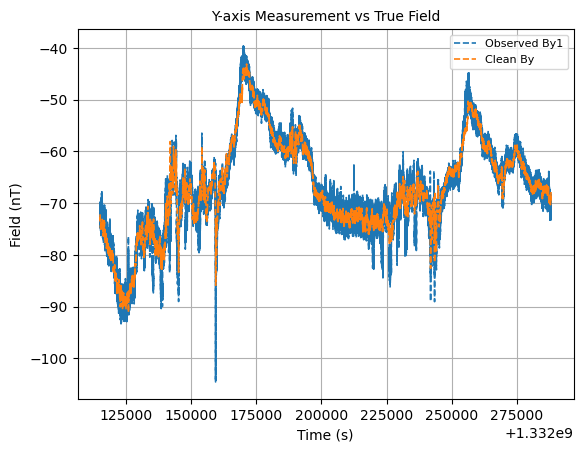

In [42]:
plt.plot(t, X_obs5[:, 1], linewidth=1.2, linestyle='--', label='Observed By1')
plt.plot(t, X_clean5[:, 1], linewidth=1.2, linestyle='--', label='Clean By')

plt.ylabel('Field (nT)')
plt.xlabel('Time (s)')
plt.grid()
plt.title('Y-axis Measurement vs True Field', fontsize=10)
plt.legend(fontsize=8)

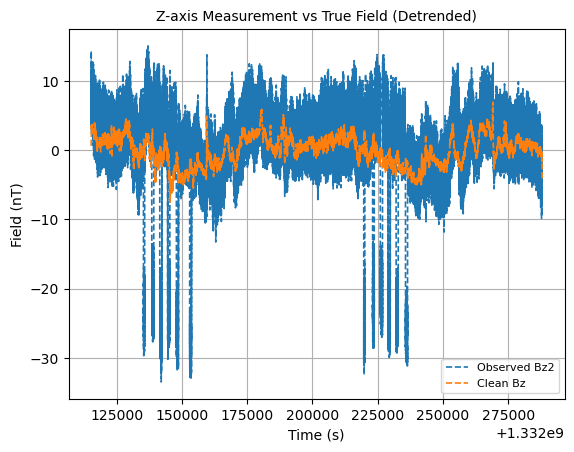

In [43]:
plt.plot(t, X_obs5[:, 5] - trend5[:, 5], linewidth=1.2, linestyle='--', label='Observed Bz2')
plt.plot(t, X_clean5[:, 5] - trend5[:, 5], linewidth=1.2, linestyle='--', label='Clean Bz')

plt.ylabel('Field (nT)')
plt.xlabel('Time (s)')
plt.grid()
plt.title('Z-axis Measurement vs True Field (Detrended)', fontsize=10)
plt.legend(fontsize=8)

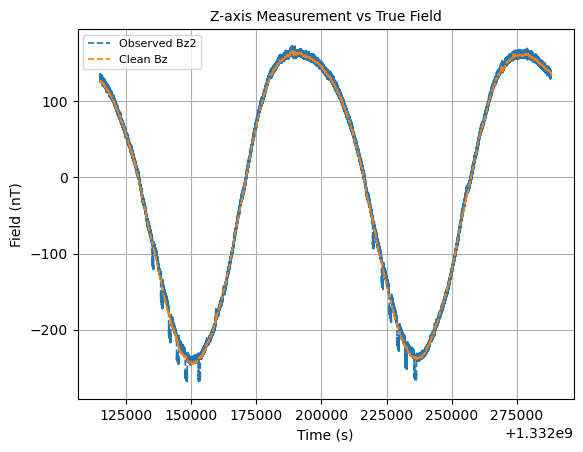

In [44]:
plt.plot(t, X_obs5[:, 5], linewidth=1.2, linestyle='--', label='Observed Bz2')
plt.plot(t, X_clean5[:, 5], linewidth=1.2, linestyle='--', label='Clean Bz')

plt.ylabel('Field (nT)')
plt.title('Z-axis Measurement vs True Field', fontsize=10)
plt.xlabel('Time (s)')
plt.grid()
plt.legend(fontsize=8)